# Fase 7 — Acoplamiento aditivo frente a difusivo

**Pregunta.** Con acoplamiento difusivo, el modo crítico es exactamente la señal global (Fase 6). ¿Cambia algo con acoplamiento aditivo, $\dot z_j=(a+i\omega)z_j+G\sum_k C_{jk}z_k$?

**Teoría** (verificada numéricamente, `src/additive.py`):
- $\mathrm{FC}=\mathrm{corr}\big[(I-\rho\hat C)^{-1}\big]$, con $\hat C=C/\lambda_{\max}$ y $\rho=G\lambda_{\max}/|a|\in(0,1)$. Coincide con Lyapunov a $10^{-15}$. La bifurcación ocurre en $\rho=1$, que es el umbral $G_c=|a|/\lambda_{\max}$, y $\kappa=1-\rho$.
- Una $\omega$ homogénea desaparece igual que antes ($9\times10^{-15}$). A diferencia del difusivo, las $\omega_j$ heterogéneas **sí** cambian la FC (0.32).
- El modo crítico es el **vector de Perron** de $C$, no el uniforme.
- Ambos modelos tienen precisión $\mathrm{diag}(q)-C$: difusivo con $q_j=\theta+d_j$, aditivo con $q=1$. Como $\mathrm{corr}(P^{-1})$ es invariante ante $P\to DPD$, la FC solo identifica las correlaciones parciales $C_{jk}/\sqrt{q_jq_k}$.

C anclada a la SC (mejor transformación), prueba en sujetos B:
  diffusive GSR=no: r test=0.238  parámetro=0.0152  kappa=0.0150
  diffusive GSR=sí: r test=0.469  parámetro=0.0000  kappa=0.0000
  additive  GSR=no: r test=0.173  parámetro=0.9916  kappa=0.0084
  additive  GSR=sí: r test=0.434  parámetro=0.9985  kappa=0.0015

kappa individual:                  ICC4   ICCdía  r(FC media)  ICC sin FC media  en límite
  aditivo SC  GSR=no   0.628  0.654   -0.995       0.304           0%
  aditivo SC  GSR=sí   0.388  0.484   +0.229       0.353           19%
  aditivo EC  GSR=no   0.609  0.635   -0.990       0.183           14%
  aditivo EC  GSR=sí   0.464  0.492   -0.299       0.431           0%
  difusivo SC GSR=no   0.628  0.654   -0.995       0.303           0%
  difusivo SC GSR=sí   0.301  0.423   +0.238       0.279           84%


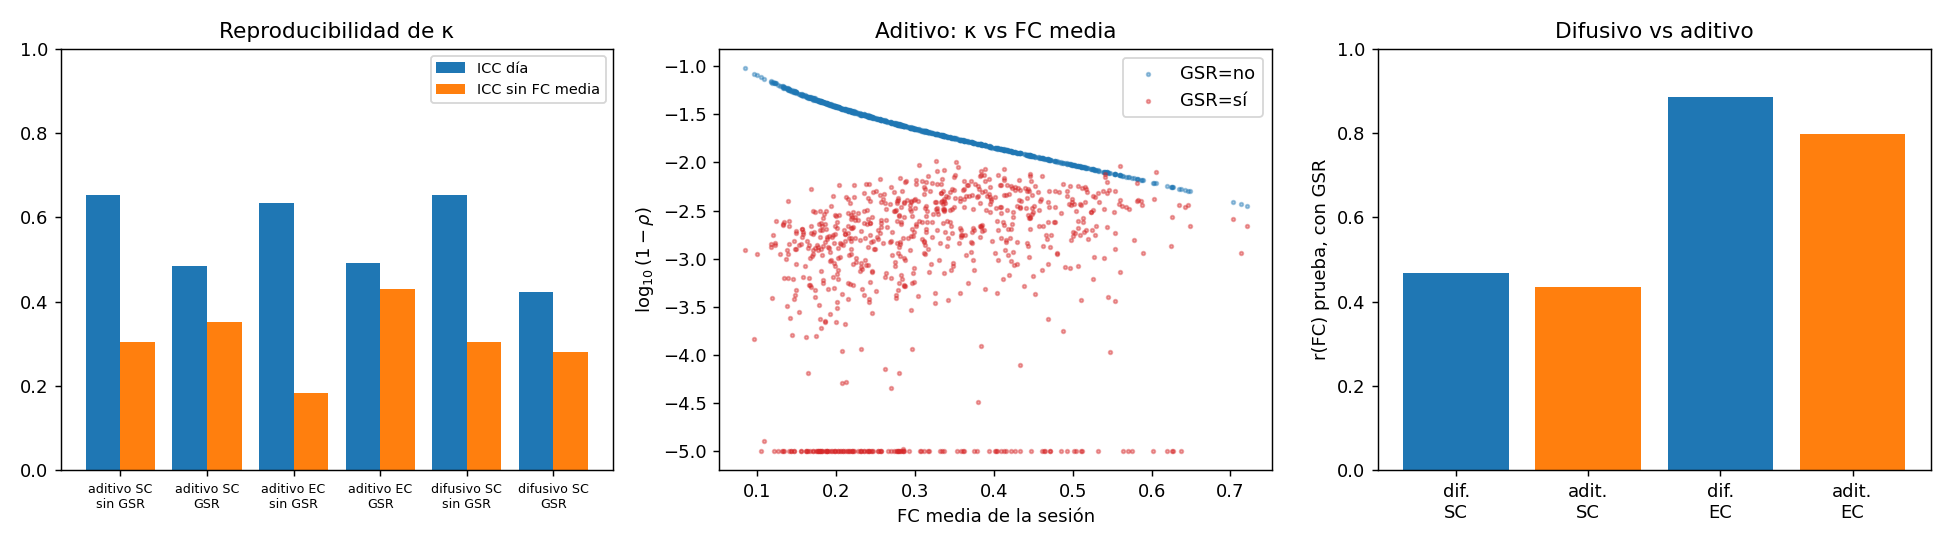

In [1]:
import numpy as np
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
r = np.load(ROOT/'results'/'fase7_additive.npz', allow_pickle=True)
print('C anclada a la SC (mejor transformación), prueba en sujetos B:')
for row in r['best']:
    kind, g, rtr, rte, p, ka = row
    print(f"  {kind:9s} GSR={'sí' if g else 'no'}: r test={rte:.3f}  parámetro={p:.4f}  kappa={ka:.4f}")
print('\nkappa individual:                  ICC4   ICCdía  r(FC media)  ICC sin FC media  en límite')
for row in r['stats']:
    print(f"  {row[0]:11s} GSR={'sí' if row[1] else 'no'}   {row[2]:.3f}  {row[3]:.3f}   {row[4]:+.3f}       {row[5]:.3f}           {row[6]:.0%}")
display(Image(str(ROOT/'figures'/'fase7_aditivo.png')))

## Resultados

**1. Los datos favorecen ligeramente al acoplamiento difusivo.** Esto se ve con la conectividad anclada a la SC (con GSR, 0.47 frente a 0.43 en los sujetos de prueba) y, de forma más clara, con EC libre (0.89 frente a 0.80). La EC difusiva alcanza $r=0.885$ en los sujetos de prueba con GSR, una mejora respecto a la Fase 6 (0.80) por partir de un $\theta$ mejor. Las correlaciones parciales que implican los dos modelos coinciden en $r=0.78$: se parecen, pero no son la misma solución.

**2. Con la C anclada a la SC, los dos modelos empujan hacia el límite crítico.** El difusivo da $\theta\to0$ y el aditivo $\rho=0.9985$. Con EC libre, el aditivo queda en $\rho=0.58$, lejos de la bifurcación: la EC absorbe la estructura y $\rho$ pierde su significado como "cercanía a la criticalidad".

**3. El modo crítico vuelve a ser casi la señal global.** El vector de Perron de la mejor $C$ ($\mathrm{SC}^{0.25}$ con refuerzo homotópico) tiene un coseno de **0.989** con el vector uniforme; con la SC cruda, 0.82. En consecuencia:
- sin GSR, $\log\kappa$ correlaciona $-0.995$ con la FC media;
- con GSR, la ICC entre días baja a 0.48, el 19 % de las sesiones queda en el límite, y el orden de los sujetos **cambia según el modelo**: $r=-0.36$ entre aditivo con SC y aditivo con EC.

## Por qué el resultado es general
Por el **teorema de Perron–Frobenius**, el eigenvector principal de una matriz de acoplamiento no negativa e irreducible es estrictamente positivo. Su coseno con el vector uniforme está acotado por debajo:
$$\cos(v,\mathbf 1)=\frac{\sum_j v_j}{\sqrt N\,\|v\|}\;\ge\;\frac{2\sqrt{v_{\min}v_{\max}}}{v_{\min}+v_{\max}}\quad\text{(desigualdad de Pólya–Szegő)}.$$
En una red densa y moderadamente heterogénea, como el conectoma a escala de 100 regiones, $v_{\max}/v_{\min}$ es pequeño y el modo crítico **es** casi la señal global. Esto vale para *cualquier* modelo lineal con acoplamiento positivo, difusivo o aditivo.

**Conclusión:** con FC a retardo cero, la distancia a la criticalidad de modelos con acoplamiento excitatorio queda **confundida con la señal global** sin importar el tipo de acoplamiento. Separarlas exige información temporal: el modo crítico se distingue de los artefactos globales por su **dinámica**, es decir, por su autocorrelación y su espectro, y se puede limpiar con regresores fisiológicos en lugar de GSR.